# 문제 정형화와 평가지표 실습: 문제를 직접 정해 보기

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/slides/ml1/week01/2_problem_formulation/lab/problem_formulation.ipynb)

모델보다 먼저 **다섯 칸** 을 채운다: ① 한 행은 무엇? ② 입력 X ③ 출력 y ④ 평가지표 ⑤ 기준선.

- **파트 1**: 타구: 같은 데이터로 두 문제 (홈런인가 분류 · 비거리 회귀), 정확도 · MAE · 기준선 직접 만들기
- **파트 2**: 다음 시즌 홈런 수: 기준선 (작년 그대로) vs kNN · 선형회귀, 시간 순서로 나누기
- **파트 3**: 2024년 모든 타석: 정확도의 함정, 정밀도 · 재현율, 한 행을 타석 → 타자로

`None` 으로 비워 둔 `TODO` 줄을 채우고 셀을 차례로 실행하세요. 코드 칸 아래의 **예상 결과** 와 비교하면 맞았는지 바로 알 수 있습니다.

In [ ]:
import json, os, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

## 파트 1. 타구: 같은 데이터, 두 문제

먼저 채점 함수 세 개를 만든다. 정답 `y_true` 와 예측 `y_pred` 를 받는다.
- 정확도 = 맞힌 개수 ÷ 전체
- MAE = 오차 절댓값의 평균
- RMSE = 오차 제곱의 평균에 루트

In [ ]:
def accuracy(y_true, y_pred):
    return None   # TODO: fraction of exact matches

def mae(y_true, y_pred):
    return None   # TODO: mean of |error|

def rmse(y_true, y_pred):
    return None   # TODO: sqrt of mean of error^2

print("accuracy:", accuracy([0, 1, 2, 2], [0, 1, 1, 2]))          # 0.75
print("MAE :", mae([0, 0, 0, 0], [1, 1, 1, 9]))                  # slide: 3
print("RMSE:", round(rmse([0, 0, 0, 0], [1, 1, 1, 9]), 2))       # slide: 4.58

**예상 결과**

```
accuracy: 0.75
MAE : 3.0
RMSE: 4.58
```

2024년 6월 MLB 정규시즌에서 **인플레이로 날아간 타구** 를 Baseball Savant (MLB Statcast) 에서 받는다. 한 행 = 타구 하나. 로그인 없이 받을 수 있고, 처음엔 1분쯤 걸린다 (약 17MB).

- `launch_speed`: 타구 속도 (mph → km/h 로 바꾼다), `launch_angle`: 발사각 (도)
- `hit_distance_sc`: 비거리 (피트 → m 로 바꾼다), `events`: 결과 (`home_run`, `single`, `field_out` …)

In [ ]:
os.makedirs("data", exist_ok=True)
SAVANT = ("https://baseballsavant.mlb.com/statcast_search/csv?all=true&type=details&player_type=batter"
          "&hfGT=R%7C&hfSea=2024%7C&hfPR=hit%5C.%5C.into%5C.%5C.play%7C&game_date_gt=2024-06-01&game_date_lt=2024-06-30")
PATH = "data/statcast_2024_06_in_play.csv"
if not os.path.exists(PATH):
    req = urllib.request.Request(SAVANT, headers={"User-Agent": "book-ml-course"})
    with urllib.request.urlopen(req, timeout=300) as r, open(PATH, "wb") as f:
        f.write(r.read())

df = pd.read_csv(PATH)[["game_date", "launch_speed", "launch_angle", "hit_distance_sc", "events"]].dropna().reset_index(drop=True)
df["speed_kmh"] = df["launch_speed"] * 1.609
df["distance_m"] = df["hit_distance_sc"] * 0.3048
df["home_run"] = (df["events"] == "home_run").astype(int)
print(df.shape, " home runs:", df["home_run"].sum())
df.head(3)

**예상 결과**

```
(20506, 8)  home runs: 915
    game_date  launch_speed  launch_angle  hit_distance_sc     events  \
0  2024-06-30          93.2          15.0            259.0     double   
1  2024-06-30          88.0          48.0            268.0  field_out   
2  2024-06-30          83.3           0.0             46.0     single   

   speed_kmh  distance_m  home_run  
0   149.9588     78.9432         0  
1   141.5920     81.6864         0  
2   134.0297     14.0208         0  
```

### 문제 A: 타구 속도 · 발사각 → 홈런인가 (분류)

공이 방망이에 맞은 **순간** 알 수 있는 것만 입력으로 쓴다: 속도, 각도, 그리고 각도². (너무 낮게 뜨거나 너무 높이 뜨면 홈런이 안 되니, 각도의 제곱을 넣어 '가운데가 좋은' 모양을 만들 수 있게 한다.)

학습 70% · 시험 30% (홈런 비율을 맞춰서). **기준선** = 늘 '홈런 아님' 이라고 답하기.

In [ ]:
X = None   # TODO: columns speed_kmh, launch_angle, launch_angle**2
y_a = None   # TODO: the home_run column (0/1)
idx_tr, idx_te = train_test_split(np.arange(len(df)), test_size=0.3, stratify=y_a, random_state=0)

base_pred = np.zeros(len(idx_te), dtype=int)          # always 'not a home run'
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X[idx_tr], y_a[idx_tr])
print(f"baseline (always 'no HR'): accuracy {accuracy(y_a[idx_te], base_pred):.1%}")
print(f"logistic regression      : accuracy {accuracy(y_a[idx_te], clf.predict(X[idx_te])):.1%}")

**예상 결과**

```
baseline (always 'no HR'): accuracy 95.5%
logistic regression      : accuracy 96.7%
```

### 문제 B: 같은 타구, 같은 입력 → 비거리 (회귀)

이번엔 `y` 가 비거리 (m). 입력은 문제 A 와 같다. **비거리는 입력에 넣으면 안 된다** (답을 입력에 넣는 셈이다). 같은 행으로 학습 · 시험을 나눈다. **기준선** = 학습 데이터의 평균 비거리를 늘 답하기.

In [ ]:
y_b = None   # TODO: the distance_m column

base_pred = np.full(len(idx_te), y_b[idx_tr].mean())
reg = make_pipeline(StandardScaler(), LinearRegression()).fit(X[idx_tr], y_b[idx_tr])
print(f"baseline (always {y_b[idx_tr].mean():.1f} m): MAE {mae(y_b[idx_te], base_pred):.1f} m  RMSE {rmse(y_b[idx_te], base_pred):.1f} m")
print(f"linear regression        : MAE {mae(y_b[idx_te], reg.predict(X[idx_te])):.1f} m  RMSE {rmse(y_b[idx_te], reg.predict(X[idx_te])):.1f} m")

**예상 결과**

```
baseline (always 50.4 m): MAE 37.5 m  RMSE 41.7 m
linear regression        : MAE 25.0 m  RMSE 29.3 m
```

**생각해 보기**: 문제 A 의 정확도 (96.7%) 와 기준선 (95.5%) 의 차이는 1.2%p 뿐이다. 그런데 모델은 시험의 홈런 275개 중 몇 개를 맞혔을까? `clf.predict(X[idx_te])` 로 세어 보자. 그리고 문제 B 의 입력에 `distance_m` 을 넣으면 MAE 가 얼마가 되는지, 그 점수가 왜 의미 없는지 말해 보자.

## 파트 2. 다음 시즌 홈런 수: 기준선이 모델을 이길 수 있다

MLB 공식 기록 (MLB Stats API) 에서 2021~2024 정규시즌 타자 기록을 받는다. 한 행 = 타자의 한 시즌. 올해 기록으로 **내년 홈런 수** 를 맞힌다.

**시간 순서대로** 나눈다: 2021→2022, 2022→2023 으로 학습, 2023→2024 로 시험. 두 해 모두 300타석 이상인 타자만 쓴다.

In [ ]:
STATS = "https://statsapi.mlb.com/api/v1/stats?stats=season&group=hitting&season={}&sportIds=1&playerPool=ALL&limit=3000&gameType=R"
COLS = {"pa": "plateAppearances", "ab": "atBats", "h": "hits", "hr": "homeRuns", "bb": "baseOnBalls", "so": "strikeOuts"}

def load_season(year):
    path = f"data/hitting_{year}.json"
    if not os.path.exists(path):
        req = urllib.request.Request(STATS.format(year), headers={"User-Agent": "book-ml-course"})
        with urllib.request.urlopen(req, timeout=60) as r, open(path, "wb") as f:
            f.write(r.read())
    splits = json.load(open(path))["stats"][0]["splits"]
    rows = [dict(pid=s["player"]["id"], name=s["player"]["fullName"], **{k: s["stat"][v] for k, v in COLS.items()}) for s in splits]
    return pd.DataFrame(rows).sort_values("pid").reset_index(drop=True)

seasons = {year: load_season(year) for year in (2021, 2022, 2023, 2024)}
for year, s in seasons.items():
    print(year, "batters:", len(s), " PA:", s["pa"].sum(), " HR:", s["hr"].sum())

**예상 결과**

```
2021 batters: 1374  PA: 181818  HR: 5944
2022 batters: 794  PA: 182052  HR: 5215
2023 batters: 769  PA: 184104  HR: 5868
2024 batters: 742  PA: 182449  HR: 5453
```

In [ ]:
def make_pairs(this_year, next_year, min_pa=300):
    """One row per batter: this year's stats + next year's PA and HR (both years >= min_pa)"""
    m = this_year.merge(next_year[["pid", "pa", "hr"]], on="pid", suffixes=("", "_next"))
    return m[(m["pa"] >= min_pa) & (m["pa_next"] >= min_pa)].reset_index(drop=True)

train = pd.concat([make_pairs(seasons[2021], seasons[2022]), make_pairs(seasons[2022], seasons[2023])], ignore_index=True)
test = make_pairs(seasons[2023], seasons[2024])
print("train", len(train), " test", len(test))
test[["name", "pa", "hr", "hr_next"]].sort_values("hr", ascending=False).head(5)

**예상 결과**

```
train 394  test 207
               name   pa  hr  hr_next
62       Matt Olson  720  54       29
102  Kyle Schwarber  720  47       38
65      Pete Alonso  658  46       34
109   Shohei Ohtani  599  44       54
15    Marcell Ozuna  592  40       39
```

기준선 두 개와 모델 두 개를 비교한다.
- 기준선 1: 늘 학습 데이터의 평균 (내년 홈런 수)
- 기준선 2: **작년 그대로** (올해 홈런 수를 내년에도 친다)
- kNN 모델 (k = 3): 올해 기록 (타석 · 타수 · 안타 · 홈런 · 볼넷 · 삼진) 이 비슷한 타자 3명의 내년 홈런 평균
- 선형회귀: 올해 홈런 하나만 입력

In [ ]:
FEATURES = ["pa", "ab", "h", "hr", "bb", "so"]
y_test = test["hr_next"].values

pred_mean = np.full(len(test), train["hr_next"].mean())
pred_last = None   # TODO: this year's HR, unchanged

scaler = StandardScaler().fit(train[FEATURES])
knn = KNeighborsRegressor(3).fit(scaler.transform(train[FEATURES]), train["hr_next"])
pred_knn = knn.predict(scaler.transform(test[FEATURES]))
lin = LinearRegression().fit(train[["hr"]], train["hr_next"])
pred_lin = lin.predict(test[["hr"]])

results = {"training mean": pred_mean, "same as last year": pred_last, "kNN (k=3)": pred_knn, "linear (HR only)": pred_lin}
for name, pred in results.items():
    print(f"{name:18s} MAE {mae(y_test, pred):.2f}")
print(f"linear: next = {lin.coef_[0]:.2f} x this + {lin.intercept_:.1f}")
plt.figure(figsize=(7, 3)); plt.bar(results.keys(), [mae(y_test, p) for p in results.values()], color=["gray", "navy", "red", "green"])
plt.ylabel("test MAE (home runs)"); plt.xticks(fontsize=8); plt.show()

**예상 결과**

```
training mean      MAE 7.35
same as last year  MAE 6.42
kNN (k=3)          MAE 6.65
linear (HR only)   MAE 5.66
linear: next = 0.61 x this + 6.0
```

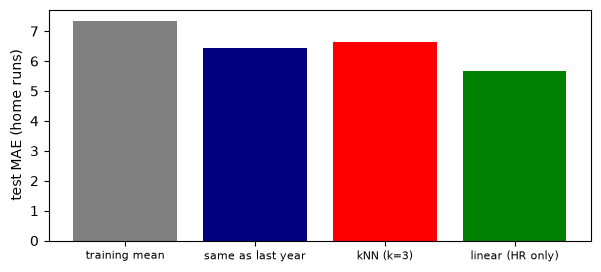

**관찰**: kNN 모델 (6.65) 이 '작년 그대로' (6.42) 보다 못하다. 기준선을 재 보지 않았다면 몰랐을 일이다. 선형회귀는 작년 홈런에 0.61 을 곱하고 6 을 더한다. 많이 친 타자는 조금 덜, 적게 친 타자는 조금 더 칠 거라고 **평균 쪽으로 당긴다**.

**생각해 보기**: 예측에 '올해 홈런 비율 × **내년 실제 타석 수**' 를 쓰면 MAE 가 더 좋아진다 (해 보자). 그런데 왜 이 숫자는 믿으면 안 될까?

## 파트 3. 2024년 모든 타석: 정확도의 함정

파트 2 에서 받은 2024 기록으로 **한 행 = 타석 하나** 인 데이터를 만든다. 타자마다 타석 수만큼 행을 만들고, 홈런 수만큼은 `y = 1`, 나머지는 `y = 0` 이다. (어느 타석이 홈런이었는지 순서는 모르지만, 개수를 세는 지표에는 상관없다.)

In [ ]:
def plate_appearances(season):
    """One row per plate appearance: batter id and y (1 = home run)"""
    s = season[season["pa"] > 0]
    pid = np.repeat(s["pid"].values, s["pa"].values)
    y = np.concatenate([np.r_[np.ones(hr, dtype=int), np.zeros(pa - hr, dtype=int)] for pa, hr in zip(s["pa"], s["hr"])])
    return pid, y

pa_pid, y = plate_appearances(seasons[2024])
print("plate appearances:", len(y), "  home runs:", y.sum(), f"({y.mean():.2%})")

all_no = None   # TODO: predict 0 (no HR) for every plate appearance
print(f"'always no HR' accuracy: {accuracy(y, all_no):.2%}")

**예상 결과**

```
plate appearances: 182449   home runs: 5453 (2.99%)
'always no HR' accuracy: 97.01%
```

정확도가 매우 높지만 홈런을 하나도 못 잡는다. 규칙 하나를 만들어 보자: **2023년에 30홈런 이상 친 타자가 서면 '홈런'**.

In [ ]:
s23 = seasons[2023]
sluggers = s23.loc[s23["hr"] >= 30, "pid"]
print("2023 sluggers (30+ HR):", len(sluggers))
rule = None   # TODO: 1 if the batter is a slugger, else 0
print(f"rule accuracy: {accuracy(y, rule):.2%}")

**예상 결과**

```
2023 sluggers (30+ HR): 29
rule accuracy: 88.68%
```

### 정밀도와 재현율: 세는 법을 바꾼다

- **재현율** = 잡았다 ÷ 실제 홈런 전부 (실제 홈런 중 몇 개를 잡았나)
- **정밀도** = 잡았다 ÷ '홈런' 이라고 한 것 전부 (찍은 것 중 진짜는 몇 개)

(3주차 정밀도와 재현율에서 자세히 다룬다.)

In [ ]:
def precision_recall(y_true, y_pred):
    tp = np.sum((y_pred == 1) & (y_true == 1))     # caught
    fp = np.sum((y_pred == 1) & (y_true == 0))     # false alarm
    fn = np.sum((y_pred == 0) & (y_true == 1))     # missed
    precision = None   # TODO: caught / everything we called HR
    recall = None      # TODO: caught / all real HRs
    return tp, fp, fn, precision, recall

for name, pred in [("always no HR", all_no), ("rule: 30+ HR last year", rule)]:
    tp, fp, fn, p, r = precision_recall(y, pred)
    print(f"{name:24s} caught {tp:4d}  false alarms {fp:6d}  missed {fn:5d}  precision {p:.2%}  recall {r:.1%}")

**예상 결과**

```
always no HR             caught    0  false alarms      0  missed  5453  precision 0.00%  recall 0.0%
rule: 30+ HR last year   caught  800  false alarms  15992  missed  4653  precision 4.76%  recall 14.7%
```

### 한 행 = 타자 한 명

이번엔 타자 한 명 (2024 시즌) 을 한 행으로, **홈런을 한 번이라도 쳤으면 1** 로 정해 보자.

In [ ]:
s24 = seasons[2024][seasons[2024]["pa"] > 0]
batter_y = None   # TODO: 1 if the batter hit at least one HR
print("batters:", len(batter_y), "  with a HR:", batter_y.sum(), f"({batter_y.mean():.1%})")
print(f"plate-appearance rate {y.mean():.2%}  ->  batter rate {batter_y.mean():.1%}")

**예상 결과**

```
batters: 651   with a HR: 522 (80.2%)
plate-appearance rate 2.99%  ->  batter rate 80.2%
```

**관찰**: 같은 기록인데 한 행을 무엇으로 정하느냐에 따라 '홈런 비율' 이 2.99% 에서 80.2% 로 바뀐다.

**생각해 보기**: 타석에 서기 **전에** 예측한다면 볼카운트 (2볼 2스트라이크 …) 를 입력에 넣을 수 있을까? 한 행을 **투구 하나** 로 바꾸면 어떻게 될까?

**확인 질문**
1. 파트 1 문제 A 에서 정확도가 기준선보다 1.2%p 높다. 이 모델은 쓸 만한가? 홈런을 몇 개 잡았는지로 말해 보자.
2. 파트 2 에서 kNN 이 '작년 그대로' 에 진 이유는 무엇일까? (힌트: 비슷한 타자 3명의 내년은 얼마나 들쭉날쭉할까?)
3. 파트 3 에서 '전부 홈런' 이라고 답하면 재현율과 정밀도는 각각 얼마가 될까?
4. 파트 2 의 시험 데이터를 2023→2024 대신 모든 해를 섞어 무작위로 뽑으면 무엇이 문제일까?

데이터 출처: Baseball Savant (MLB Statcast) · MLB Stats API (statsapi.mlb.com).